## **Explainable Machine Learning Modelling on WHO Life Expectancy Dataset**

This notebook develops an end-to-end machine learning workflow using the WHO Life Expectancy dataset. The task is to predict male and female life expectancy using health, economic, and demographic variables. The workflow includes data loading, exploratory data analysis, feature engineering, preprocessing, PCA, model training, AutoML comparison, hyperparameter tuning, evaluation, and explainable AI interpretation.

**Leakage correction:** Any average life-expectancy variable created for exploratory analysis is stored only in `df_eda` and is never included in the model feature matrix. Preprocessing and PCA are also placed inside the hyperparameter-search pipelines so that they are fitted separately within every cross-validation fold.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Life Expectancy Data v2.csv to Life Expectancy Data v2 (1).csv


## **Data Loading**

The dataset is loaded into the notebook using pandas. The first few rows are displayed to understand the structure of the data, including the available columns and example values.

In [ ]:
import pandas as pd

df = pd.read_csv("Life Expectancy Data v2.csv")

print(df.head())

       Country  Year      Status  Life expectancy (men)  \
0  Afghanistan  2015  Developing                     70   
1  Afghanistan  2014  Developing                     59   
2  Afghanistan  2013  Developing                     79   
3  Afghanistan  2012  Developing                     65   
4  Afghanistan  2011  Developing                     76   

   Life expectancy(women)  Adult Mortality (men)  Adult Mortality (women)  \
0                      66                     67                       65   
1                      67                     73                       85   
2                      51                     87                       67   
3                      81                     63                       91   
4                      75                     57                       72   

   Infant deaths  Alcohol  Percentage expenditure  Hepatitis B(men)  \
0             62     0.01               71.279624                40   
1             64     0.01               

## **Importing Required Libraries**

The required Python libraries are imported for data handling, visualisation, preprocessing, PCA, machine learning model training, evaluation, AutoML, and explainable AI.

In [ ]:
# Basic libraries
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and modelling
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Settings
pd.set_option("display.max_columns", None)
sns.set(style="whitegrid")

## **Exploratory Data Analysis**

Exploratory Data Analysis is performed to understand the dataset before modelling. This includes checking the number of rows and columns, missing values, data types, summary statistics, distributions, and relationships between variables.

### **Checking Dataset Shape**

In [ ]:
print(df.shape)

(2938, 25)


### **Missing Values and Data Types**

In [ ]:
print(df.isnull().sum())

Country                              0
Year                                 0
Status                               0
Life expectancy (men)                0
Life expectancy(women)               0
Adult Mortality (men)                0
Adult Mortality (women)              0
Infant deaths                        0
Alcohol                            194
Percentage expenditure               0
Hepatitis B(men)                     0
Hepatitis B(women)                   0
Measles                              0
BMI                                 34
Under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64


### **Data Quality Check**

The dataset is checked for missing values and data types. This step helps identify which columns require preprocessing before PCA and machine learning model training.

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy (men)            2938 non-null   int64  
 4   Life expectancy(women)           2938 non-null   int64  
 5   Adult Mortality (men)            2938 non-null   int64  
 6   Adult Mortality (women)          2938 non-null   int64  
 7   Infant deaths                    2938 non-null   int64  
 8   Alcohol                          2744 non-null   float64
 9   Percentage expenditure           2938 non-null   float64
 10  Hepatitis B(men)                 2938 non-null   int64  
 11  Hepatitis B(women)               2938 non-null   int64  
 12  Measles             

### **Summary Statistics**

Summary statistics are used to understand the central tendency, spread, minimum, maximum, and general distribution of numerical variables. This gives an initial idea about the scale and range of each feature.

In [ ]:
print(df.describe(include="all"))

            Country         Year      Status  Life expectancy (men)  \
count          2938  2938.000000        2938            2938.000000   
unique          193          NaN           2                    NaN   
top     Afghanistan          NaN  Developing                    NaN   
freq             16          NaN        2426                    NaN   
mean            NaN  2007.518720         NaN              67.710007   
std             NaN     4.613841         NaN              10.346219   
min             NaN  2000.000000         NaN              50.000000   
25%             NaN  2004.000000         NaN              59.000000   
50%             NaN  2008.000000         NaN              68.000000   
75%             NaN  2012.000000         NaN              77.000000   
max             NaN  2015.000000         NaN              85.000000   

        Life expectancy(women)  Adult Mortality (men)  \
count              2938.000000            2938.000000   
unique                     NaN   

### **Distribution of Numerical Variables**

Histograms are used to visualise the distribution of numerical features. This helps identify skewness, unusual patterns, and possible outliers in the dataset.

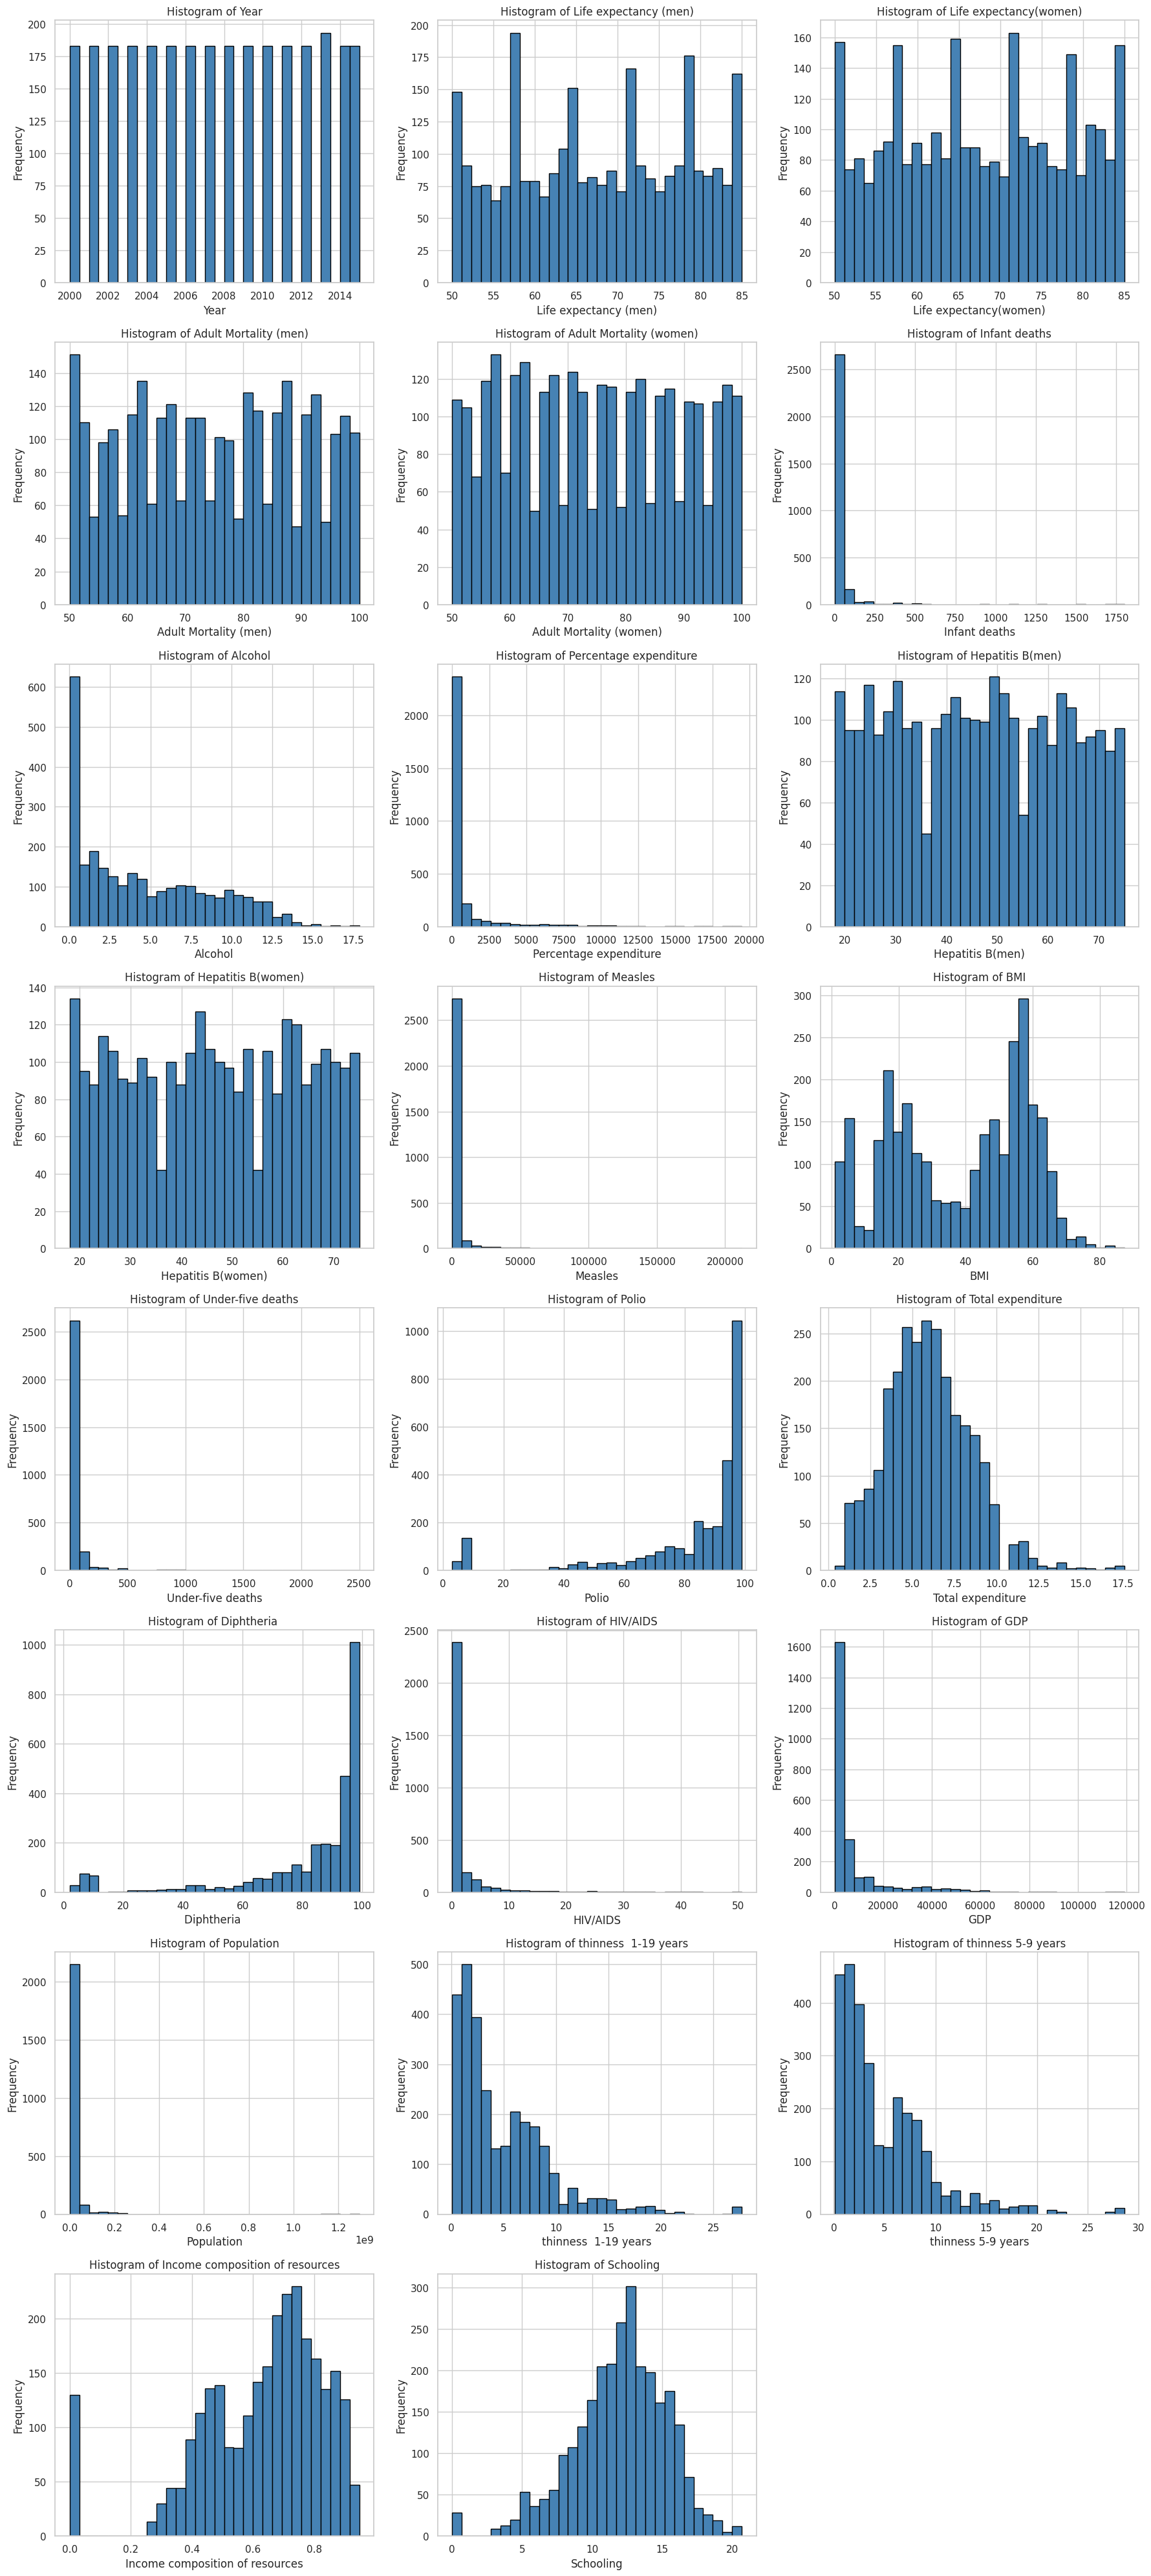

In [ ]:
import math
import matplotlib.pyplot as plt

# Select numerical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Decide matrix size
n_cols = 3   # number of plots in one row
n_rows = math.ceil(len(numeric_cols) / n_cols)

# Create subplot matrix
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

# Make axes easy to loop
axes = axes.flatten()

# Plot histograms
for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col].dropna(), bins=30, color="steelblue", edgecolor="black")
    axes[i].set_title("Histogram of " + col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# Remove empty plots if any
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### **Target Variable Distribution**

The distribution of average life expectancy is visualised only for exploratory analysis. The average is created in a separate DataFrame named `df_eda`. It is not added to the modelling DataFrame, because it is calculated directly from the two targets and would cause target leakage.

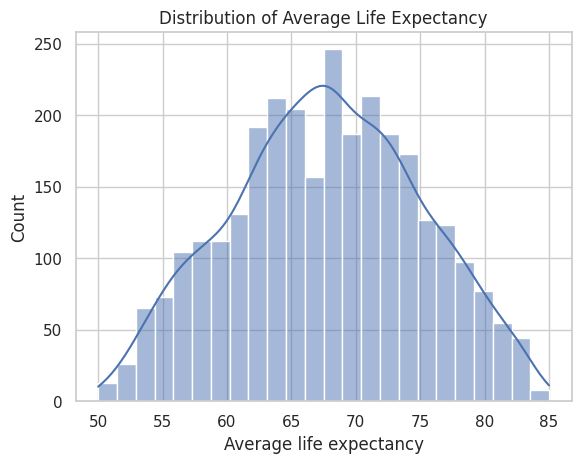

In [ ]:
# Create an EDA-only copy so the target-derived average cannot enter the model.
df_eda = df.copy()
df_eda["Average life expectancy (EDA only)"] = (
    df_eda["Life expectancy (men)"]
    + df_eda["Life expectancy(women)"]
) / 2

sns.histplot(df_eda["Average life expectancy (EDA only)"], kde=True)
plt.title("Distribution of Average Life Expectancy")
plt.xlabel("Average life expectancy")
plt.show()

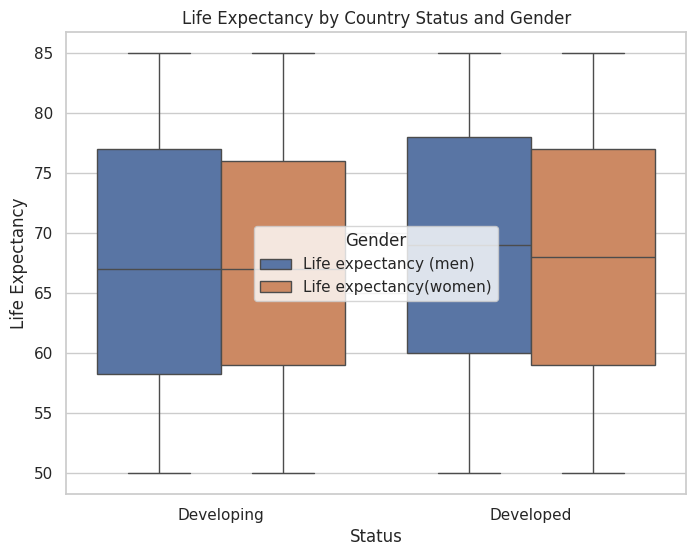

In [ ]:
# Developed vs Developing average life expectancy
# Reshape the data to plot both men and women's life expectancy
df_melted = pd.melt(
    df,
    id_vars=['Status'],
    value_vars=['Life expectancy (men)', 'Life expectancy(women)'],
    var_name='Gender',
    value_name='Life Expectancy'
)

plt.figure(figsize=(8, 6))
sns.boxplot(data=df_melted, x="Status", y="Life Expectancy", hue="Gender")
plt.title("Life Expectancy by Country Status and Gender")
plt.show()

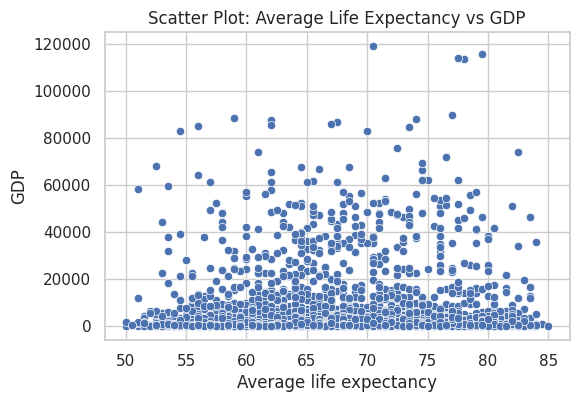

In [ ]:
# Use the EDA-only average. The original modelling DataFrame remains unchanged.
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df_eda,
    x="Average life expectancy (EDA only)",
    y="GDP"
)
plt.title("Scatter Plot: Average Life Expectancy vs GDP")
plt.xlabel("Average life expectancy")
plt.show()

### **Correlation Analysis**

A correlation heatmap is used to examine relationships between numerical variables. This helps identify strongly related features and gives insight into possible patterns that may influence life expectancy.

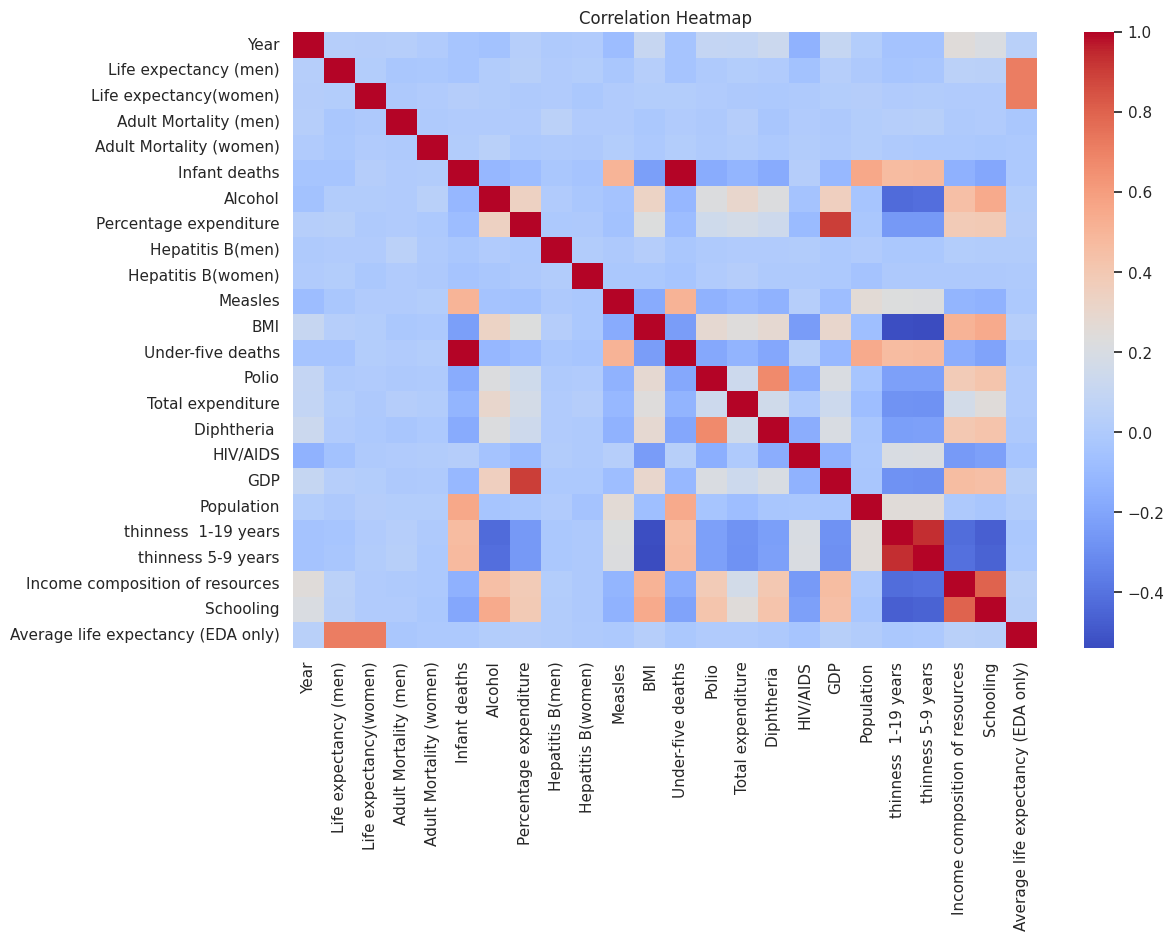

In [ ]:
# Correlation is exploratory only and is calculated from the EDA copy.
numeric_df = df_eda.select_dtypes(include=["int64", "float64"])
correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()

## **Feature and Target Selection**

The target variables are male life expectancy and female life expectancy. These columns are stored in `y` and removed from `X`, creating a multi-output regression problem. Any target-derived average column is also explicitly removed as a safety check.

### **Train-Test Split**

The dataset is split before any learned preprocessing. Imputation, scaling, encoding, and PCA are fitted using training data only. The test set is reserved for final model evaluation.

In [ ]:
target_cols = ["Life expectancy (men)", "Life expectancy(women)"]

# Use the original data for modelling, not df_eda.
model_df = df.copy()

# Defensive removal in case this notebook is rerun after an older version.
target_derived_cols = [
    "Life expectancy",
    "Average life expectancy",
    "Average life expectancy (EDA only)"
]
model_df = model_df.drop(columns=target_derived_cols, errors="ignore")

X = model_df.drop(columns=target_cols).copy()
y = model_df[target_cols].copy()

# Automatic leakage checks.
assert all(col not in X.columns for col in target_cols)
assert all(col not in X.columns for col in target_derived_cols)
print("Target leakage check passed: no target or target-derived column is in X.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Target columns:", list(y.columns))

Target leakage check passed: no target or target-derived column is in X.
Training feature shape: (2056, 23)
Testing feature shape: (882, 23)
Target columns: ['Life expectancy (men)', 'Life expectancy(women)']


## **Feature Engineering**

New features are created from existing variables to improve the information available to the model. These include health expenditure per GDP, mortality gap, and average thinness. The same feature engineering steps are applied to both training and testing data.

In [ ]:
def add_engineered_features(data):
    """Create predictor-only features without using either target."""
    data = data.copy()
    data["Health_expenditure_per_GDP"] = (
        data["Percentage expenditure"] / (data["GDP"] + 1)
    )
    data["Mortality_gap"] = (
        data["Adult Mortality (men)"]
        - data["Adult Mortality (women)"]
    )
    data["thinness_average"] = (
        data["thinness  1-19 years"]
        + data["thinness 5-9 years"]
    ) / 2
    return data


X_train = add_engineered_features(X_train)
X_test = add_engineered_features(X_test)

print("Feature engineering completed without using the targets.")

Feature engineering completed without using the targets.


## **Preprocessing Pipeline**

A preprocessing pipeline is built to handle missing values, encode categorical variables, and scale numerical variables. Numerical missing values are handled using median imputation, categorical missing values are handled using the most frequent value, categorical variables are converted using one-hot encoding, and numerical variables are standardised.

In [ ]:
# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X_train.select_dtypes(include=["object"]).columns

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

## **Applying Preprocessing**

The preprocessing pipeline is fitted only on the training data. The same fitted pipeline is then used to transform the testing data. This prevents information from the testing data from entering the training process.

In [ ]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using same fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Training data shape after preprocessing:", X_train_processed.shape)
print("Testing data shape after preprocessing:", X_test_processed.shape)

Training data shape after preprocessing: (2056, 215)
Testing data shape after preprocessing: (882, 215)


 A preprocessing pipeline was built to prepare the dataset before PCA and model training. First, the dataset was split into training and testing sets to avoid data leakage. Missing values in numerical variables were handled using median imputation because the dataset contains variables such as GDP and Population that may have outliers. Missing values in categorical variables were handled using the most frequent category. Categorical variables such as Country and Status were encoded using one-hot encoding so that they could be used by machine learning models. Numerical variables were standardised using StandardScaler because PCA and many machine learning models are sensitive to feature scale. Feature engineering was also performed by creating new variables such as health expenditure per GDP, mortality gap, and average thinness. The preprocessing pipeline was fitted only on the training data and then applied to the testing data to prevent test data leakage.

## **Principal Component Analysis**

PCA is applied after preprocessing to reduce dimensionality while retaining most of the information in the dataset. PCA is fitted only on the preprocessed training data, and the same PCA transformation is applied to the testing data.

In [ ]:
# Keep enough principal components to explain 95% variance
pca = PCA(n_components=0.95, random_state=42)

# Fit PCA only on training data
X_train_pca = pca.fit_transform(X_train_processed)

# Transform testing data using the same PCA
X_test_pca = pca.transform(X_test_processed)

## **PCA Explained Variance**

The explained variance ratio shows how much information is captured by each principal component. The cumulative explained variance plot is used to decide how many components are needed to retain 95% of the total variance.

In [ ]:
explained_variance = pca.explained_variance_ratio_

for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.4f}")

PC1: 0.2380
PC2: 0.0972
PC3: 0.0797
PC4: 0.0650
PC5: 0.0596
PC6: 0.0487
PC7: 0.0424
PC8: 0.0407
PC9: 0.0396
PC10: 0.0371
PC11: 0.0344
PC12: 0.0322
PC13: 0.0313
PC14: 0.0253
PC15: 0.0229
PC16: 0.0196
PC17: 0.0168
PC18: 0.0125
PC19: 0.0076


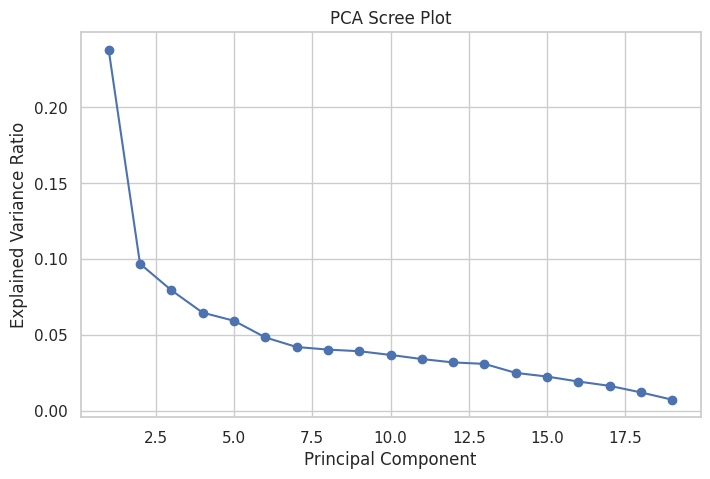

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid(True)
plt.show()

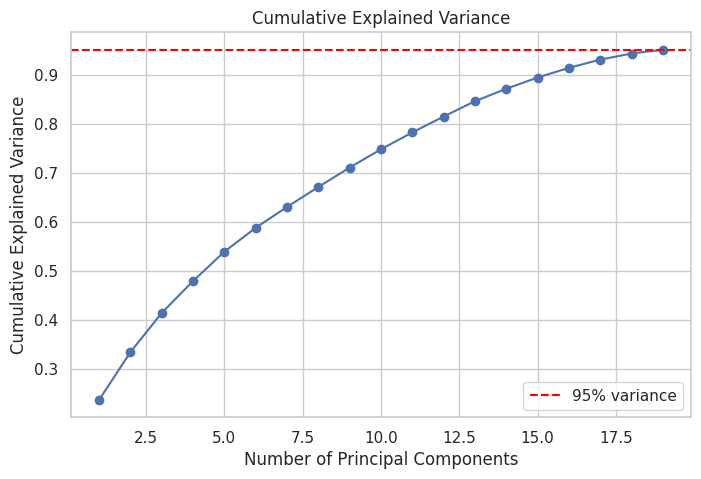

In [ ]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

## **Machine Learning Model Development**

Several regression models are trained to predict both male and female life expectancy. Linear Regression is used as a baseline model, while Random Forest and Gradient Boosting are used to capture more complex patterns in the data.

In [ ]:
target_cols = ["Life expectancy (men)", "Life expectancy(women)"]

def evaluate_model(model_name, y_test, y_pred):
    print("=" * 50)
    print("Model:", model_name)
    print("=" * 50)

    for i, target in enumerate(target_cols):
        mae = mean_absolute_error(y_test[target], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_test[target], y_pred[:, i]))
        r2 = r2_score(y_test[target], y_pred[:, i])

        print(target)
        print("MAE:", mae)
        print("RMSE:", rmse)
        print("R2 Score:", r2)
        print()

In [ ]:
lr_model = LinearRegression()

lr_model.fit(X_train_pca, y_train)

y_pred_lr = lr_model.predict(X_test_pca)

evaluate_model("Linear Regression", y_test, y_pred_lr)

Model: Linear Regression
Life expectancy (men)
MAE: 8.953599167465388
RMSE: 10.347227467459485
R2 Score: -0.0015702107518182906

Life expectancy(women)
MAE: 8.708875215487026
RMSE: 10.156284163666372
R2 Score: -0.01663144495711233



In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_pca, y_train)

y_pred_rf = rf_model.predict(X_test_pca)

evaluate_model("Random Forest Regressor", y_test, y_pred_rf)

Model: Random Forest Regressor
Life expectancy (men)
MAE: 9.014807256235827
RMSE: 10.441563563943092
R2 Score: -0.019916174944576648

Life expectancy(women)
MAE: 8.711451247165533
RMSE: 10.272122103879354
R2 Score: -0.03995416311833244



In [ ]:
from sklearn.multioutput import MultiOutputRegressor

gb_model = MultiOutputRegressor(
    GradientBoostingRegressor(random_state=42)
)

gb_model.fit(X_train_pca, y_train)

y_pred_gb = gb_model.predict(X_test_pca)

evaluate_model("Gradient Boosting Regressor", y_test, y_pred_gb)

Model: Gradient Boosting Regressor
Life expectancy (men)
MAE: 8.951532476546594
RMSE: 10.421611288965478
R2 Score: -0.016022082785526193

Life expectancy(women)
MAE: 8.74959625597668
RMSE: 10.244171831905954
R2 Score: -0.03430246700463635



## **Hyperparameter Tuning Without Cross-Validation Leakage**

`RandomizedSearchCV` is used to tune Random Forest and Gradient Boosting. The preprocessor and PCA are included inside each model pipeline. Therefore, every cross-validation fold fits its own imputer, scaler, encoder, and PCA using only that fold's training portion.

In [ ]:
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("pca", PCA(n_components=0.95, random_state=42)),
    ("model", RandomForestRegressor(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_grid,
    n_iter=10,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

# Supply raw engineered training features; preprocessing and PCA occur in each fold.
rf_random_search.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

Best Random Forest Parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_depth': 10}


In [ ]:
best_rf_pipeline = rf_random_search.best_estimator_
y_pred_best_rf = best_rf_pipeline.predict(X_test)

evaluate_model("Tuned Random Forest Regressor", y_test, y_pred_best_rf)

Model: Tuned Random Forest Regressor
Life expectancy (men)
MAE: 8.959759799943924
RMSE: 10.351109237743309
R2 Score: -0.002321831369291205

Life expectancy(women)
MAE: 8.70925955346975
RMSE: 10.17792245313761
R2 Score: -0.02096799148054118



In [ ]:
# The fitted tuning pipeline can be inspected as one complete, leakage-safe model.
best_rf_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Year', 'Adult Mortality (men)', 'Adult Mortality (women)',
       'Infant deaths', 'Alcohol', 'Percentage expenditure',
       'Hepatitis B(men)', 'Hepatitis B(women)', 'Measles', 'BMI',
       'Under-five deaths', 'Polio...
       'Health_expenditure_per_GDP', 'Mortality_gap', 'thinness_average'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index(['Country', 'Status'], dtype='object'))])),
                ('pca', PCA(n_components=0.95, random_state=42)),
                ('model',
                 RandomForestRegressor(max_depth=10, min_samples_leaf=4,
                                       random_state=42))])

In [ ]:
gb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("pca", PCA(n_components=0.95, random_state=42)),
    (
        "model",
        MultiOutputRegressor(GradientBoostingRegressor(random_state=42))
    )
])

gb_param_grid = {
    "model__estimator__n_estimators": [100, 200, 300],
    "model__estimator__learning_rate": [0.01, 0.05, 0.1],
    "model__estimator__max_depth": [2, 3, 4, 5]
}

gb_random_search = RandomizedSearchCV(
    estimator=gb_tuning_pipeline,
    param_distributions=gb_param_grid,
    n_iter=10,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

gb_random_search.fit(X_train, y_train)

print("Best Gradient Boosting Parameters:")
print(gb_random_search.best_params_)

Best Gradient Boosting Parameters:
{'model__estimator__n_estimators': 100, 'model__estimator__max_depth': 2, 'model__estimator__learning_rate': 0.05}


In [ ]:
best_gb_pipeline = gb_random_search.best_estimator_
y_pred_best_gb = best_gb_pipeline.predict(X_test)

evaluate_model("Tuned Gradient Boosting Regressor", y_test, y_pred_best_gb)

Model: Tuned Gradient Boosting Regressor
Life expectancy (men)
MAE: 8.96048897924319
RMSE: 10.368976914883504
R2 Score: -0.005785154865861397

Life expectancy(women)
MAE: 8.700001822363836
RMSE: 10.139773081082486
R2 Score: -0.013328654050381195



## **AutoML for Model Selection**

FLAML AutoML is used separately for male and female life expectancy. A validation subset is taken only from the training data. A fresh preprocessor and PCA are fitted on the AutoML training subset and then applied to the validation and final test sets. This prevents validation and test information from entering the AutoML training process.

In [ ]:
# Install AutoML and XAI packages in Google Colab.
!pip install -q "flaml[automl]" shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.0/353.0 kB 27.3 MB/s eta 0:00:00


In [ ]:
from flaml import AutoML

In [ ]:
# Create an internal validation set only from the original training data.
X_automl_train, X_automl_val, y_automl_train, y_automl_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

# Fit fresh preprocessing and PCA objects on the AutoML training subset only.
automl_preprocessor = clone(preprocessor)
X_automl_train_processed = automl_preprocessor.fit_transform(X_automl_train)
X_automl_val_processed = automl_preprocessor.transform(X_automl_val)
X_automl_test_processed = automl_preprocessor.transform(X_test)

automl_pca = PCA(n_components=0.95, random_state=42)
X_automl_train_pca = automl_pca.fit_transform(X_automl_train_processed)
X_automl_val_pca = automl_pca.transform(X_automl_val_processed)
X_automl_test_pca = automl_pca.transform(X_automl_test_processed)

automl_results = {}

for target in target_cols:
    print("Running AutoML for:", target)

    automl = AutoML()
    automl.fit(
        X_train=X_automl_train_pca,
        y_train=y_automl_train[target],
        X_val=X_automl_val_pca,
        y_val=y_automl_val[target],
        task="regression",
        time_budget=60,
        metric="mae",
        seed=42,
        verbose=0
    )

    y_pred_automl = automl.predict(X_automl_test_pca)

    mae = mean_absolute_error(y_test[target], y_pred_automl)
    rmse = np.sqrt(mean_squared_error(y_test[target], y_pred_automl))
    r2 = r2_score(y_test[target], y_pred_automl)

    automl_results[target] = {
        "Best model": automl.best_estimator,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    print("Best AutoML model:", automl.best_estimator)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)
    print()

pd.DataFrame(automl_results).T

Running AutoML for: Life expectancy (men)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Best AutoML model: lgbm
MAE: 9.067762529217283
RMSE: 10.749473555079032
R2 Score: -0.08095545457200481

Running AutoML for: Life expectancy(women)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Best AutoML model: extra_tree
MAE: 8.663259199712948
RMSE: 10.083241446961384
R2 Score: -0.002061057587209758



,Best model,MAE,RMSE,R2
Life expectancy (men),lgbm,9.067763,10.749474,-0.080955
Life expectancy(women),extra_tree,8.663259,10.083241,-0.002061


## **Model Evaluation**

The models are evaluated using MAE, RMSE, and R2 score. MAE shows the average prediction error in years, RMSE gives higher penalty to larger errors, and R2 score shows how well the model explains variation in life expectancy.

In [ ]:
target_cols = ["Life expectancy (men)", "Life expectancy(women)"]

def evaluate_model(model_name, y_test, y_pred):
    results = []

    for i, target in enumerate(target_cols):
        mae = mean_absolute_error(y_test[target], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_test[target], y_pred[:, i]))
        r2 = r2_score(y_test[target], y_pred[:, i])

        results.append({
            "Model": model_name,
            "Target": target,
            "MAE": mae,
            "RMSE": rmse,
            "R2 Score": r2
        })

    return results

In [ ]:
all_results = []

all_results += evaluate_model("Linear Regression", y_test, y_pred_lr)
all_results += evaluate_model("Random Forest", y_test, y_pred_rf)
all_results += evaluate_model("Gradient Boosting", y_test, y_pred_gb)
all_results += evaluate_model("Tuned Random Forest", y_test, y_pred_best_rf)
all_results += evaluate_model("Tuned Gradient Boosting", y_test, y_pred_best_gb)

results_df = pd.DataFrame(all_results)
results_df

,Model,Target,MAE,RMSE,R2 Score
0,Linear Regression,Life expectancy (men),8.953599,10.347227,-0.001570
1,Linear Regression,Life expectancy(women),8.708875,10.156284,-0.016631
2,Random Forest,Life expectancy (men),9.014807,10.441564,-0.019916
3,Random Forest,Life expectancy(women),8.711451,10.272122,-0.039954
4,Gradient Boosting,Life expectancy (men),8.951532,10.421611,-0.016022
5,Gradient Boosting,Life expectancy(women),8.749596,10.244172,-0.034302
6,Tuned Random Forest,Life expectancy (men),8.959760,10.351109,-0.002322
7,Tuned Random Forest,Life expectancy(women),8.709260,10.177922,-0.020968
8,Tuned Gradient Boosting,Life expectancy (men),8.960489,10.368977,-0.005785
9,Tuned Gradient Boosting,Life expectancy(women),8.700002,10.139773,-0.013329


In [ ]:
results_df.sort_values(by=["Target", "MAE"])

,Model,Target,MAE,RMSE,R2 Score
4,Gradient Boosting,Life expectancy (men),8.951532,10.421611,-0.016022
0,Linear Regression,Life expectancy (men),8.953599,10.347227,-0.001570
6,Tuned Random Forest,Life expectancy (men),8.959760,10.351109,-0.002322
8,Tuned Gradient Boosting,Life expectancy (men),8.960489,10.368977,-0.005785
2,Random Forest,Life expectancy (men),9.014807,10.441564,-0.019916
9,Tuned Gradient Boosting,Life expectancy(women),8.700002,10.139773,-0.013329
1,Linear Regression,Life expectancy(women),8.708875,10.156284,-0.016631
7,Tuned Random Forest,Life expectancy(women),8.709260,10.177922,-0.020968
3,Random Forest,Life expectancy(women),8.711451,10.272122,-0.039954
5,Gradient Boosting,Life expectancy(women),8.749596,10.244172,-0.034302


In [ ]:
summary_results = results_df.groupby("Model")[["MAE", "RMSE", "R2 Score"]].mean()
summary_results.sort_values(by="MAE")

,MAE,RMSE,R2 Score
Model,,,
Tuned Gradient Boosting,8.830245,10.254375,-0.009557
Linear Regression,8.831237,10.251756,-0.009101
Tuned Random Forest,8.834510,10.264516,-0.011645
Gradient Boosting,8.850564,10.332892,-0.025162
Random Forest,8.863129,10.356843,-0.029935


## **Model Comparison**

Bar charts are used to compare model performance across both target variables. MAE and R2 score are visualised to identify which model performs best overall.

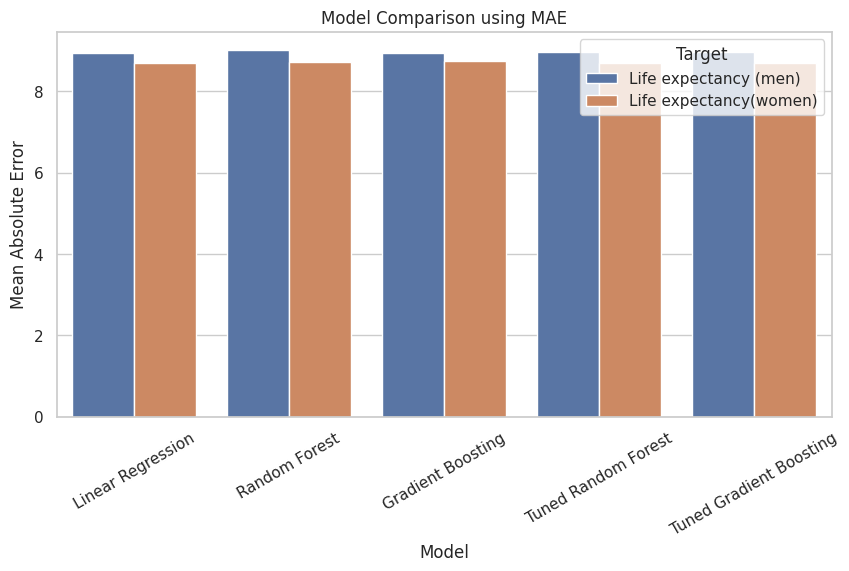

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MAE", hue="Target")
plt.xticks(rotation=30)
plt.title("Model Comparison using MAE")
plt.ylabel("Mean Absolute Error")
plt.show()

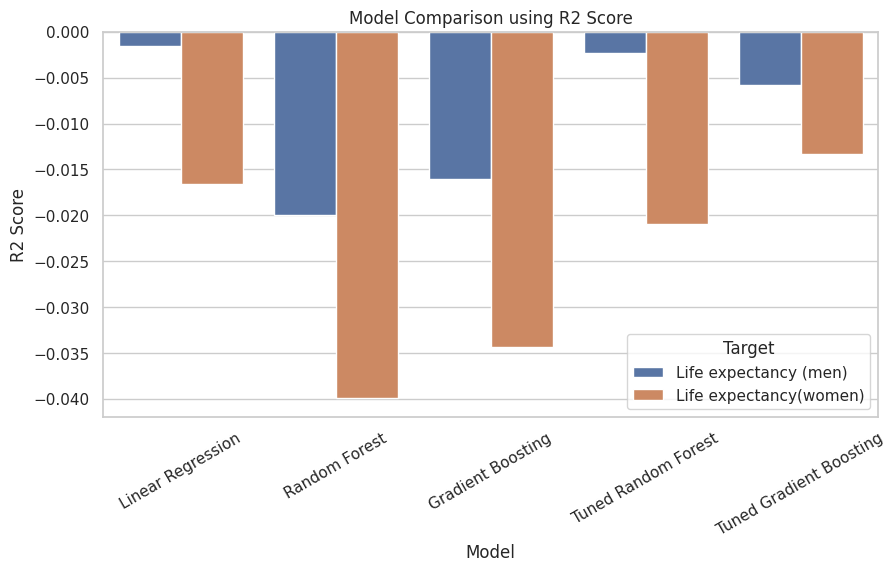

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score", hue="Target")
plt.xticks(rotation=30)
plt.title("Model Comparison using R2 Score")
plt.ylabel("R2 Score")
plt.show()

### **Model Comparison Using MAE and R²**

**MAE comparison:** Lower MAE indicates better predictions. All five models have similar errors, approximately 8.7–9.0 years. This means their predictions differ from the actual life expectancy values by roughly nine years on average. Female life expectancy predictions have slightly lower MAE than male predictions across all models. Hyperparameter tuning produces only small changes, so the MAE results do not show a substantial advantage for a particular model.

**R² comparison:** Higher R² indicates better performance. All models have negative R² scores, meaning they perform worse than predicting the test-set mean for every observation when measured by squared error. Linear Regression has the highest R² for male life expectancy, while Tuned Gradient Boosting has the highest R² for female life expectancy. Random Forest has the lowest scores for both targets. Tuning improves the R² scores of Random Forest and Gradient Boosting, but they remain negative.

Together, these results show limited predictive performance. More complex models and hyperparameter tuning do not provide a clear, consistent improvement, suggesting that the dataset quality, available predictive information, and preprocessing choices need further investigation.

## **Explainable AI Interpretation**

Explainable AI is applied to the tuned Random Forest pipeline because it provides tree-based component importance for both targets. The preprocessing and PCA objects are taken directly from the fitted tuning pipeline. PCA loadings connect important components back to the original transformed features, while SHAP shows how the components affect predictions.

In [ ]:
# Extract the fitted stages from the leakage-safe tuned Random Forest pipeline.
xai_preprocessor = best_rf_pipeline.named_steps["preprocessor"]
xai_pca = best_rf_pipeline.named_steps["pca"]
xai_model = best_rf_pipeline.named_steps["model"]

X_train_xai = xai_pca.transform(xai_preprocessor.transform(X_train))
X_test_xai = xai_pca.transform(xai_preprocessor.transform(X_test))

In [ ]:
pc_names = [f"PC{i+1}" for i in range(X_train_xai.shape[1])]

importance_df = pd.DataFrame({
    "Principal Component": pc_names,
    "Importance": xai_model.feature_importances_
})

importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df.head(10)

,Principal Component,Importance
7,PC8,0.067082
6,PC7,0.062104
2,PC3,0.060336
8,PC9,0.059159
5,PC6,0.056968
16,PC17,0.056431
18,PC19,0.056190
14,PC15,0.055680
3,PC4,0.052677
15,PC16,0.052482


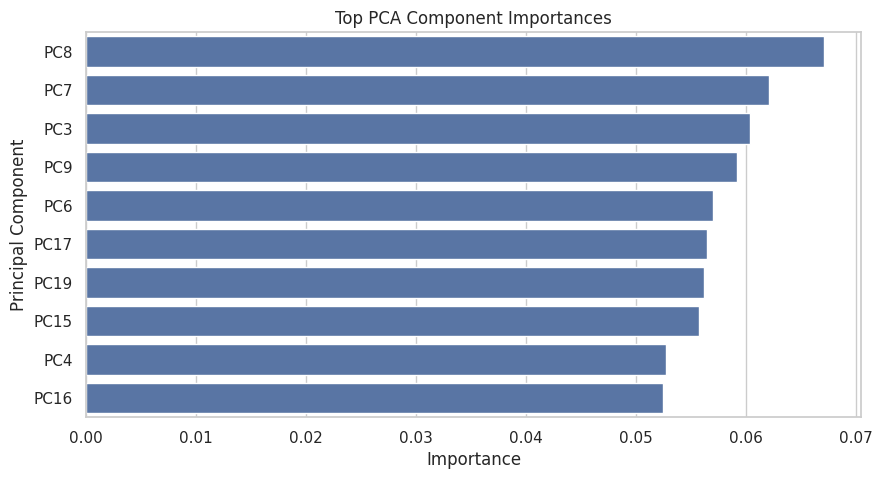

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df.head(10), x="Importance", y="Principal Component")
plt.title("Top PCA Component Importances")
plt.show()

In [ ]:
feature_names = xai_preprocessor.get_feature_names_out()

loadings = pd.DataFrame(
    xai_pca.components_,
    columns=feature_names,
    index=pc_names
)

loadings.head()

,num__Year,num__Adult Mortality (men),num__Adult Mortality (women),num__Infant deaths,num__Alcohol,num__Percentage expenditure,num__Hepatitis B(men),num__Hepatitis B(women),num__Measles,num__BMI,num__Under-five deaths,num__Polio,num__Total expenditure,num__Diphtheria,num__HIV/AIDS,num__GDP,num__Population,num__thinness 1-19 years,num__thinness 5-9 years,num__Income composition of resources,num__Schooling,num__Health_expenditure_per_GDP,num__Mortality_gap,num__thinness_average,cat__Country_Afghanistan,cat__Country_Albania,cat__Country_Algeria,cat__Country_Angola,cat__Country_Antigua and Barbuda,cat__Country_Argentina,cat__Country_Armenia,cat__Country_Australia,cat__Country_Austria,cat__Country_Azerbaijan,cat__Country_Bahamas,cat__Country_Bahrain,cat__Country_Bangladesh,cat__Country_Barbados,cat__Country_Belarus,cat__Country_Belgium,cat__Country_Belize,cat__Country_Benin,cat__Country_Bhutan,cat__Country_Bolivia (Plurinational State of),cat__Country_Bosnia and Herzegovina,cat__Country_Botswana,cat__Country_Brazil,cat__Country_Brunei Darussalam,cat__Country_Bulgaria,cat__Country_Burkina Faso,cat__Country_Burundi,cat__Country_Cabo Verde,cat__Country_Cambodia,cat__Country_Cameroon,cat__Country_Canada,cat__Country_Central African Republic,cat__Country_Chad,cat__Country_Chile,cat__Country_China,cat__Country_Colombia,cat__Country_Comoros,cat__Country_Congo,cat__Country_Cook Islands,cat__Country_Costa Rica,cat__Country_Croatia,cat__Country_Cuba,cat__Country_Cyprus,cat__Country_Czechia,cat__Country_Côte d'Ivoire,cat__Country_Democratic People's Republic of Korea,cat__Country_Democratic Republic of the Congo,cat__Country_Denmark,cat__Country_Djibouti,cat__Country_Dominica,cat__Country_Dominican Republic,cat__Country_Ecuador,cat__Country_Egypt,cat__Country_El Salvador,cat__Country_Equatorial Guinea,cat__Country_Eritrea,cat__Country_Estonia,cat__Country_Ethiopia,cat__Country_Fiji,cat__Country_Finland,cat__Country_France,cat__Country_Gabon,cat__Country_Gambia,cat__Country_Georgia,cat__Country_Germany,cat__Country_Ghana,cat__Country_Greece,cat__Country_Grenada,cat__Country_Guatemala,cat__Country_Guinea,cat__Country_Guinea-Bissau,cat__Country_Guyana,cat__Country_Haiti,cat__Country_Honduras,cat__Country_Hungary,cat__Country_Iceland,cat__Country_India,cat__Country_Indonesia,cat__Country_Iran (Islamic Republic of),cat__Country_Iraq,cat__Country_Ireland,cat__Country_Israel,cat__Country_Italy,cat__Country_Jamaica,cat__Country_Japan,cat__Country_Jordan,cat__Country_Kazakhstan,cat__Country_Kenya,cat__Country_Kiribati,cat__Country_Kuwait,cat__Country_Kyrgyzstan,cat__Country_Lao People's Democratic Republic,cat__Country_Latvia,cat__Country_Lebanon,cat__Country_Lesotho,cat__Country_Liberia,cat__Country_Libya,cat__Country_Lithuania,cat__Country_Luxembourg,cat__Country_Madagascar,cat__Country_Malawi,cat__Country_Malaysia,cat__Country_Maldives,cat__Country_Mali,cat__Country_Malta,cat__Country_Mauritania,cat__Country_Mauritius,cat__Country_Mexico,cat__Country_Micronesia (Federated States of),cat__Country_Monaco,cat__Country_Mongolia,cat__Country_Montenegro,cat__Country_Morocco,cat__Country_Mozambique,cat__Country_Myanmar,cat__Country_Namibia,cat__Country_Nauru,cat__Country_Nepal,cat__Country_Netherlands,cat__Country_New Zealand,cat__Country_Nicaragua,cat__Country_Niger,cat__Country_Nigeria,cat__Country_Norway,cat__Country_Oman,cat__Country_Pakistan,cat__Country_Palau,cat__Country_Panama,cat__Country_Papua New Guinea,cat__Country_Paraguay,cat__Country_Peru,cat__Country_Philippines,cat__Country_Poland,cat__Country_Portugal,cat__Country_Qatar,cat__Country_Republic of Korea,cat__Country_Republic of Moldova,cat__Country_Romania,cat__Country_Russian Federation,cat__Country_Rwanda,cat__Country_Saint Kitts and Nevis,cat__Country_Saint Lucia,cat__Country_Saint Vincent and the Grenadines,cat__Country_Samoa,cat__Country_Sao Tome and Principe,cat__Country_Saudi Arabia,cat__Country_Senegal,cat__Country_Serbia,cat__Country_Seychelles,cat__Country_Sierra Leone,cat__Countr

In [ ]:
loadings.loc["PC1"].abs().sort_values(ascending=False).head(10)

,PC1
num__thinness_average,0.345691
num__thinness 5-9 years,0.340613
num__thinness 1-19 years,0.339367
num__Schooling,0.294812
num__Income composition of resources,0.274019
num__BMI,0.271860
num__Under-five deaths,0.236017
num__Infant deaths,0.232355
num__Alcohol,0.232178
num__GDP,0.206486


In [ ]:
top_pc = importance_df.iloc[0]["Principal Component"]

print("Most important PCA component:", top_pc)

loadings.loc[top_pc].abs().sort_values(ascending=False).head(10)

Most important PCA component: PC8


,PC8
num__Hepatitis B(women),0.837637
num__Total expenditure,0.266478
num__HIV/AIDS,0.206374
num__Year,0.203567
num__Hepatitis B(men),0.185874
num__Adult Mortality (men),0.168441
num__Health_expenditure_per_GDP,0.160752
num__Alcohol,0.150597
num__Adult Mortality (women),0.109636
num__Population,0.065518


## **SHAP Analysis**

SHAP is used to explain how the model makes predictions. Separate SHAP summary plots are generated for male and female life expectancy to show which PCA components contribute most to each prediction target.

In [ ]:
import shap
import numpy as np

In [ ]:
# Use a manageable background/sample size for SHAP.
X_sample = X_train_xai[:100]

explainer = shap.Explainer(xai_model.predict, X_sample)
shap_values = explainer(X_sample)

PermutationExplainer explainer: 101it [00:34,  2.06it/s]


/tmp/ipykernel_776/219583109.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


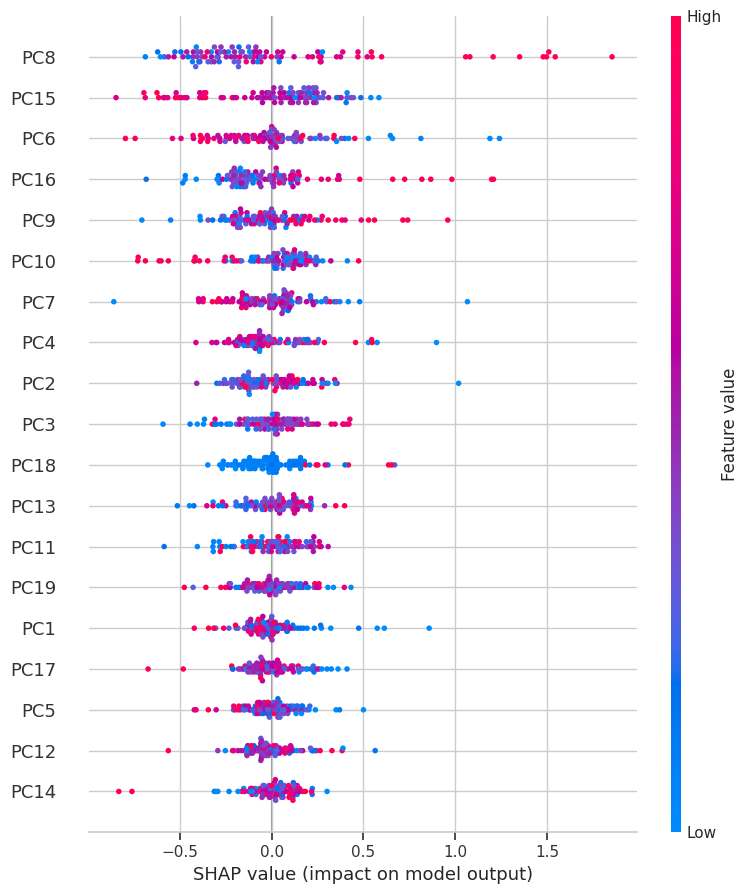

In [ ]:
shap.summary_plot(
    shap_values.values[:, :, 0],
    X_sample,
    feature_names=pc_names,
    show=True
)

/tmp/ipykernel_776/881426421.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


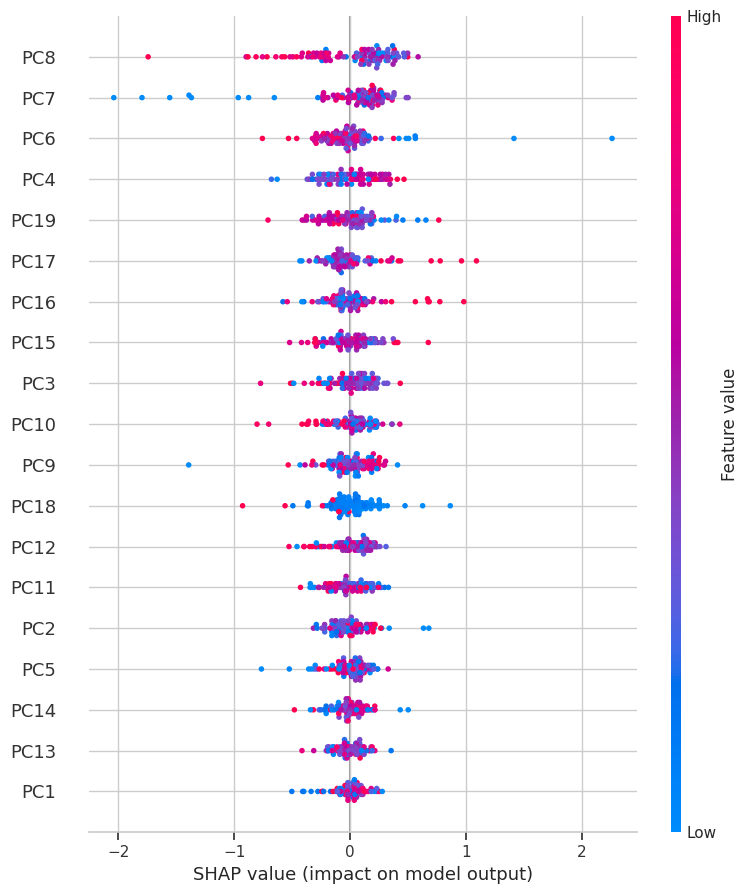

In [ ]:
shap.summary_plot(
    shap_values.values[:, :, 1],
    X_sample,
    feature_names=pc_names,
    show=True
)

## **Conclusion**

This notebook completed an end-to-end machine learning workflow for predicting male and female life expectancy. The workflow included data-quality checks, EDA, feature engineering, preprocessing, PCA, model training, hyperparameter tuning, AutoML comparison, evaluation, and explainable AI. Target-derived variables were excluded from the predictors, and preprocessing and PCA were fitted on training data to prevent information leakage.

The validation-selected AutoML model achieved an average test MAE of approximately **8.88 years** and an average R² of **−0.032**. These results show limited predictive ability, with no improvement over the median baseline’s average test MAE of approximately **8.81 years**. The training and cross-validation comparisons also showed that more complex models could overfit without improving predictions on unseen data.

Since the models used principal components, global and individual SHAP explanations were applied to understand how these components affected predictions. Permutation importance provided an additional comparison, while PCA loadings connected important components to the original transformed variables. These explanations describe model behaviour rather than causal relationships. Further work should verify the dataset’s source and sex-specific columns, investigate the weak predictive signal, and evaluate alternative representations using appropriately separated data.